# Credit Risk Scoring — Notebook 1: EDA & Data Cleaning
## India Personal Loan Default Risk 2026

---

### What This Notebook Covers
| Step | Description |
|:---|:---|
| **Step 1** | Data Audit — shape, dtypes, class imbalance, missing values, leakage scan |
| **Step 2** | Data Cleaning — impossible values, stratified split, winsorization |
| **Step 3** | Exploratory Data Analysis — 6 focused business-insight charts |
| **Step 4** | Feature Engineering — 7 Indian banking financial ratios |

> **Why Notebooks?** Notebooks combine code, visual output, and plain-English explanation in one scrollable document. An interviewer can read this top-to-bottom and understand not just *what* you did, but *why* — which is what separates a good candidate from a great one.

---
## Setup — Imports & Configuration

In [188]:
import sys, os, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.model_selection import train_test_split

# ── Visual style ─────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (10, 5)})
COLORS = {'default': '#E74C3C', 'non_default': '#2ECC71',
          'blue': '#3498DB', 'orange': '#E67E22'}

# ── Paths ─────────────────────────────────────────────────────
DATA_RAW   = '../data/raw/india_personal_loan_default_risk_2026.csv'
DATA_PROC  = '../data/processed/'
RESULTS    = '../results/'
TARGET     = 'default_flag'
ID_COL     = 'applicant_id'
LEAKAGE    = ['default_risk_score']
RANDOM_STATE = 42

print('Imports complete. Working from:', os.path.abspath('../'))

Imports complete. Working from: c:\Users\Kartik Kumar Singh\Desktop\predictive analysis


---
# STEP 1 — Data Audit

> **Why we do this first:**  
> Before writing a single line of ML code, you must understand what you're working with. Data scientists who skip the audit phase often build models on corrupted data, include leakage columns, or miss severe class imbalance — all of which produce misleadingly good training metrics that collapse on real-world data.
>
> Key questions we answer here:
> - How many rows and features do we have?
> - Is the target balanced or imbalanced?
> - Are there missing values, duplicates, or impossible values?
> - Does any column contain information that wouldn't exist at prediction time (leakage)?

### 1.1 Load Raw Data

In [189]:
df = pd.read_csv(DATA_RAW)
print(f'Dataset shape  →  {df.shape[0]:,} rows  ×  {df.shape[1]} columns')
df.head(3)

Dataset shape  →  25,000 rows  ×  22 columns


,applicant_id,age,gender,marital_status,city_tier,state,employment_type,bank_account_vintage_years,monthly_income_inr,existing_loans_count,...,num_credit_inquiries_last_6m,late_payments_last_12m,loan_amount_requested_inr,loan_tenure_months,loan_purpose,collateral_provided,cibil_score,interest_rate_offered_pct,default_risk_score,default_flag
0,APP106868,22,Male,Single,Tier 3,Haryana,Salaried - PSU,0.5,12000,1,...,2.0,0,149000,48,Personal Expense,No,649,24.84,1.67,0
1,APP124016,35,Female,Divorced,Tier 2,Gujarat,Salaried - Private,0.5,32500,3,...,0.0,1,156000,60,Personal Expense,No,538,25.25,4.47,0
2,APP109668,41,Male,Married,Tier 2,Uttar Pradesh,Salaried - Government,2.8,52500,0,...,0.0,0,70000,36,Wedding,No,636,20.46,0.19,0


### 1.2 Column Data Types

Understanding dtypes tells us which columns need encoding (categoricals) vs imputation and scaling (numerics). It also surfaces any columns that look numeric but are stored as strings.

In [190]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   applicant_id                  25000 non-null  str    
 1   age                           25000 non-null  int64  
 2   gender                        25000 non-null  str    
 3   marital_status                25000 non-null  str    
 4   city_tier                     25000 non-null  str    
 5   state                         25000 non-null  str    
 6   employment_type               25000 non-null  str    
 7   bank_account_vintage_years    24625 non-null  float64
 8   monthly_income_inr            25000 non-null  int64  
 9   existing_loans_count          25000 non-null  int64  
 10  existing_emi_monthly_inr      24500 non-null  float64
 11  credit_utilization_ratio_pct  25000 non-null  float64
 12  num_credit_inquiries_last_6m  24750 non-null  float64
 13  late_payment

### 1.3 Target Distribution — Class Imbalance

> **This is the most important single observation in the audit.**  
> With ~6% defaults, a naive model that predicts "no default" for everyone would achieve 93.86% accuracy — but it would catch **zero** actual defaulters. This tells us:
> 1. We must use `class_weight='balanced'` or cost-sensitive learning
> 2. We must evaluate with **PR-AUC and Recall**, NOT plain Accuracy
> 3. We must use **stratified splits** to preserve the 6:94 ratio in both train and test

Target Distribution:
              Count  Percentage (%)
default_flag                       
0             23465           93.86
1              1535            6.14

Class imbalance ratio  →  1 : 15.3
Naive "always 0" accuracy  →  93.86%  ← Misleading!


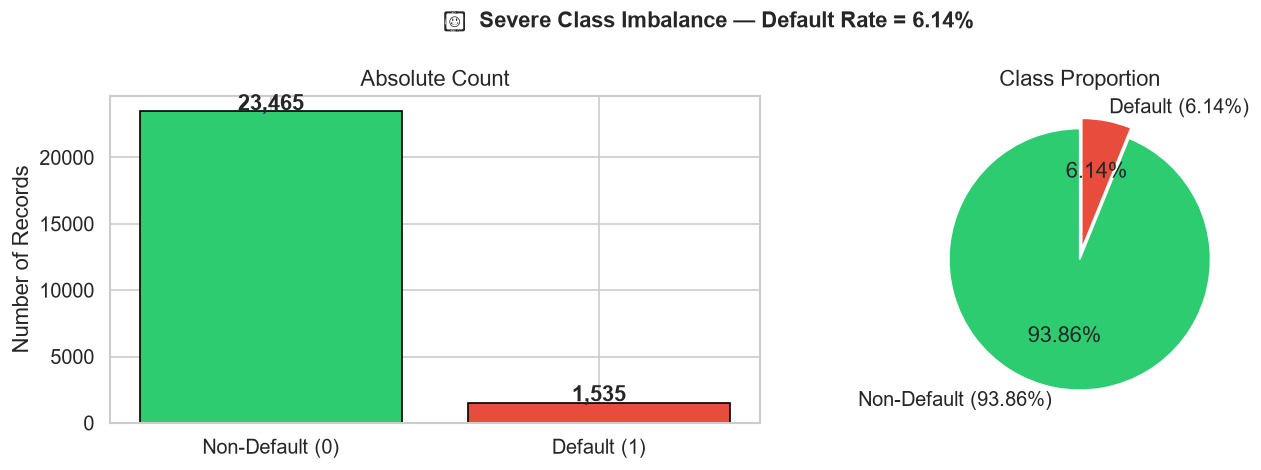

In [191]:
dist = df[TARGET].value_counts()
pct  = df[TARGET].value_counts(normalize=True) * 100

print('Target Distribution:')
print(pd.DataFrame({'Count': dist, 'Percentage (%)': pct.round(2)}))
print(f'\nClass imbalance ratio  →  1 : {dist[0]/dist[1]:.1f}')
print(f'Naive "always 0" accuracy  →  {pct[0]:.2f}%  ← Misleading!')

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['Non-Default (0)', 'Default (1)'], dist.values,
            color=[COLORS['non_default'], COLORS['default']], edgecolor='black')
axes[0].set(title='Absolute Count', ylabel='Number of Records')
for bar, val in zip(axes[0].patches, dist.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+100,
                 f'{val:,}', ha='center', fontweight='bold')

axes[1].pie(dist.values, labels=['Non-Default (93.86%)', 'Default (6.14%)'],
            colors=[COLORS['non_default'], COLORS['default']],
            autopct='%1.2f%%', startangle=90, explode=[0, 0.08])
axes[1].set_title('Class Proportion')
plt.suptitle('⚠  Severe Class Imbalance — Default Rate = 6.14%', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.4 Missing Values

> **Strategy:** We do NOT drop rows with missing values (that would remove 1,125 records and potentially bias the sample). Instead, we apply **median imputation inside a Pipeline** that is fit only on training data — this prevents any test information from leaking into the imputation step.

Columns with missing values:


,Missing Count,Missing %
existing_emi_monthly_inr,500,2.0
bank_account_vintage_years,375,1.5
num_credit_inquiries_last_6m,250,1.0


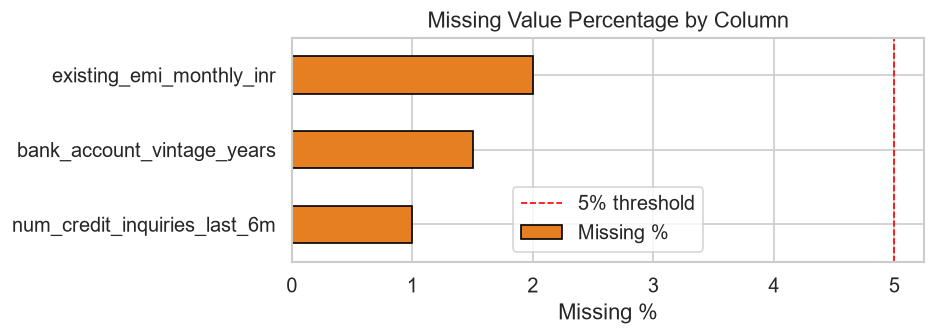


Total records affected: 1,110
All missing columns are NUMERIC → will apply median imputation in pipeline


In [192]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
mv_df = pd.DataFrame({'Missing Count': missing,
                       'Missing %':     (missing/len(df)*100).round(2)})
print('Columns with missing values:')
display(mv_df)

# Visualise
fig, ax = plt.subplots(figsize=(8, 3))
mv_df['Missing %'].sort_values().plot(kind='barh', ax=ax, color=COLORS['orange'], edgecolor='black')
ax.set(title='Missing Value Percentage by Column', xlabel='Missing %')
ax.axvline(5, color='red', linestyle='--', linewidth=1, label='5% threshold')
ax.legend()
plt.tight_layout()
plt.show()

print(f'\nTotal records affected: {df[missing.index].isna().any(axis=1).sum():,}')
print('All missing columns are NUMERIC → will apply median imputation in pipeline')

### 1.5 Duplicate Rows

In [193]:
dupes = df.duplicated().sum()
print(f'Duplicate rows: {dupes}')
print('No duplicates — dataset is clean on this front.')

Duplicate rows: 0
No duplicates — dataset is clean on this front.


### 1.6 Descriptive Statistics & Outlier Scan

In [194]:
desc = df.describe().T
desc['skew'] = df.select_dtypes(include=np.number).skew()
desc[['min','max','mean','50%','std','skew']].round(2)

,min,max,mean,50%,std,skew
age,21.00,65.00,35.30,35.00,8.56,0.27
bank_account_vintage_years,0.50,25.00,4.00,2.80,3.90,1.90
monthly_income_inr,12000.00,727000.00,54832.43,45100.00,38347.49,2.79
existing_loans_count,0.00,6.00,1.10,1.00,1.05,0.96
existing_emi_monthly_inr,0.00,202300.00,11705.64,9000.00,10297.37,2.96
credit_utilization_ratio_pct,0.00,100.00,41.59,41.30,19.80,0.12
num_credit_inquiries_last_6m,0.00,9.00,1.30,1.00,1.14,0.88
late_payments_last_12m,0.00,8.00,1.45,1.00,1.27,0.95
loan_amount_requested_inr,25000.00,1519000.00,158457.24,133000.00,104231.47,2.29
loan_tenure_months,12.00,84.00,42.40,36.00,19.22,0.32


In [195]:
# ── Impossible value check ────────────────────────────────────
checks = {
    'age':                          (18, 100),
    'cibil_score':                  (300, 900),
    'credit_utilization_ratio_pct': (0, 100),
    'monthly_income_inr':           (1, None),
    'loan_amount_requested_inr':    (1, None),
    'interest_rate_offered_pct':    (0, 50),
}
print('Impossible Value Scan:')
for col, (lo, hi) in checks.items():
    s = df[col].dropna()
    flags = []
    if lo is not None and (s < lo).any():  flags.append(f'< {lo}: {(s<lo).sum()} rows')
    if hi is not None and (s > hi).any():  flags.append(f'> {hi}: {(s>hi).sum()} rows')
    status = ' | '.join(flags) if flags else 'OK'
    print(f'  {col:<40} {status}')

Impossible Value Scan:
  age                                      OK
  cibil_score                              OK
  credit_utilization_ratio_pct             OK
  monthly_income_inr                       OK
  loan_amount_requested_inr                OK
  interest_rate_offered_pct                OK


### 1.7 Leakage Detection — `default_risk_score`

> **Data Leakage** is the #1 silent killer of ML projects. It occurs when a feature contains information that wouldn't be available at prediction time, or when it was constructed using the target label.
>
> `default_risk_score` is suspicious — it looks like it was computed *from* the same underwriting model that generated `default_flag`. If we keep it, models will simply learn to read this score instead of learning real borrower patterns. We test its correlation with the target.

Pearson correlation  'default_risk_score' ↔ 'default_flag'  =  0.4840
  ⚠  Moderate-high correlation (0.4840) — DROPPING to prevent leakage


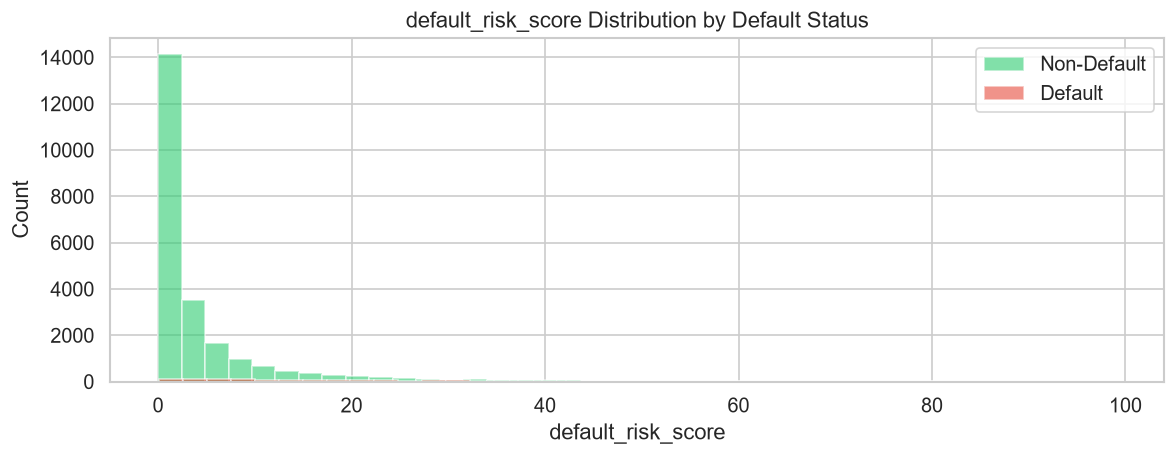


→ Conclusion: default_risk_score will be DROPPED before modelling.


In [196]:
for col in LEAKAGE:
    if col in df.columns:
        r = df[col].corr(df[TARGET])
        print(f"Pearson correlation  '{col}' ↔ '{TARGET}'  =  {r:.4f}")
        if abs(r) > 0.3:
            print(f"  ⚠  Moderate-high correlation ({r:.4f}) — DROPPING to prevent leakage")
        else:
            print(f"  ✓  Low correlation — may keep")

# Also look at how default_risk_score distributes across the target
fig, ax = plt.subplots(figsize=(10, 4))
for flag, color, lbl in [(0, COLORS['non_default'], 'Non-Default'), (1, COLORS['default'], 'Default')]:
    df.loc[df[TARGET]==flag, 'default_risk_score'].plot(
        kind='hist', bins=40, alpha=0.6, color=color, label=lbl, ax=ax)
ax.set(title='default_risk_score Distribution by Default Status',
       xlabel='default_risk_score', ylabel='Count')
ax.legend()
plt.tight_layout()
plt.show()
print('\n→ Conclusion: default_risk_score will be DROPPED before modelling.')

### 1.8 Categorical Unique Values

In [197]:
cat_cols = df.select_dtypes(include='object').columns
for c in cat_cols:
    print(f'  {c:<35} {df[c].nunique():>3} unique  →  {df[c].dropna().unique().tolist()[:6]}')

  applicant_id                        25000 unique  →  ['APP106868', 'APP124016', 'APP109668', 'APP113640', 'APP114018', 'APP107488']
  gender                                3 unique  →  ['Male', 'Female', 'Other']
  marital_status                        4 unique  →  ['Single', 'Divorced', 'Married', 'Widowed']
  city_tier                             3 unique  →  ['Tier 3', 'Tier 2', 'Tier 1']
  state                                15 unique  →  ['Haryana', 'Gujarat', 'Uttar Pradesh', 'Kerala', 'Punjab', 'Andhra Pradesh']
  employment_type                       5 unique  →  ['Salaried - PSU', 'Salaried - Private', 'Salaried - Government', 'Self-Employed Professional', 'Business Owner']
  loan_purpose                          8 unique  →  ['Personal Expense', 'Wedding', 'Education', 'Business Expansion', 'Debt Consolidation', 'Home Renovation']
  collateral_provided                   2 unique  →  ['No', 'Yes']


---
#  STEP 2 — Data Cleaning & Train/Test Split

> **The Golden Rule of ML Data Prep:**  
> **Split FIRST, transform AFTER.**
>
> If you compute medians, standard deviations, or one-hot encodings on the full dataset *before* splitting, you are accidentally letting test-set statistics influence your training transformations. This is called **data leakage** — it makes your cross-validation metrics optimistic and unreliable.
>
> Correct order:
> 1. Drop ID and leakage columns
> 2. Fix impossible values (data-entry errors)
> 3. **Stratified split** (80/20)
> 4. All imputation, scaling, encoding → inside `Pipeline` → fit only on train folds

### 2.1 Drop ID and Leakage Columns

In [198]:
drop_cols = [ID_COL] + LEAKAGE
df_clean  = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(f'Dropped columns: {[c for c in drop_cols if c in df.columns]}')
print(f'Remaining shape: {df_clean.shape}')

Dropped columns: ['applicant_id', 'default_risk_score']
Remaining shape: (25000, 20)


### 2.2 Fix Impossible Values

We nullify clear data-entry errors (e.g., CIBIL score of 1200) rather than dropping rows. The pipeline's imputer will fill them. This is safer than deletion because:
- Dropping rows from the minority class (defaults) makes the imbalance even worse
- Median imputation on a small number of extreme errors has minimal impact

In [199]:
df_c = df_clean.copy()

# CIBIL outside [300, 900]
bad_cibil = (df_c['cibil_score'] < 300) | (df_c['cibil_score'] > 900)
df_c.loc[bad_cibil, 'cibil_score'] = np.nan

# Age outside [18, 100]
bad_age = (df_c['age'] < 18) | (df_c['age'] > 100)
df_c.loc[bad_age, 'age'] = np.nan

# Credit utilisation clamped to [0, 100]
df_c['credit_utilization_ratio_pct'] = df_c['credit_utilization_ratio_pct'].clip(0, 100)

# Negative income / loan amount → null
for col in ['monthly_income_inr', 'loan_amount_requested_inr']:
    neg = df_c[col] < 0
    df_c.loc[neg, col] = np.nan

print(f'Rows after cleaning: {len(df_c):,}  (unchanged — we nullified, not deleted)')
print(f'Missing values now:  {df_c.isna().sum().sum()}')

Rows after cleaning: 25,000  (unchanged — we nullified, not deleted)
Missing values now:  1125


### 2.3 Stratified Train / Test Split (80% / 20%)

We use `stratify=y` to ensure both splits preserve the 6.14% default rate. Without stratification, random chance could give us a test set with 4% or 8% defaults — making our evaluation metrics unrepresentative.

Train set  →  20,000 rows  |  Default rate: 6.14%
Test set   →  5,000  rows  |  Default rate: 6.14%

Stratification preserved the 6.14% default rate in both splits.


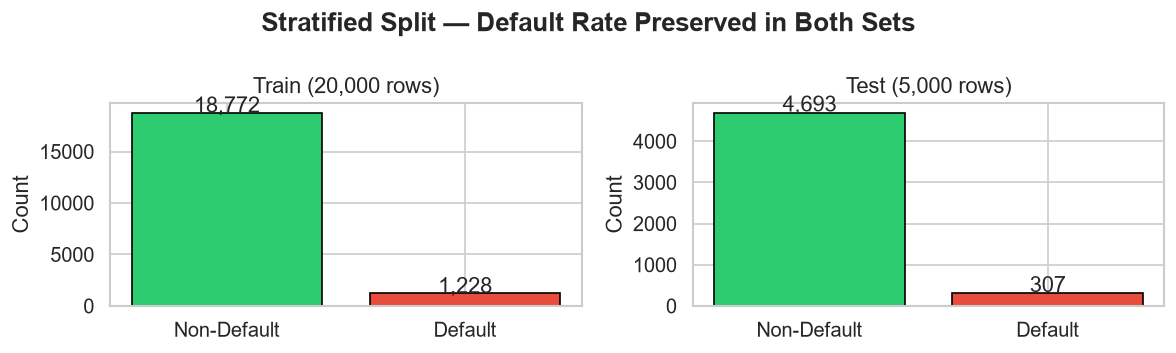

In [200]:
X = df_c.drop(columns=[TARGET])
y = df_c[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Train set  →  {len(X_train):,} rows  |  Default rate: {y_train.mean()*100:.2f}%')
print(f'Test set   →  {len(X_test):,}  rows  |  Default rate: {y_test.mean()*100:.2f}%')
print('\nStratification preserved the 6.14% default rate in both splits.')

# Visual confirmation
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, y_s, title in [(axes[0], y_train, 'Train (20,000 rows)'), (axes[1], y_test, 'Test (5,000 rows)')]:
    counts = y_s.value_counts()
    ax.bar(['Non-Default', 'Default'], counts.values,
           color=[COLORS['non_default'], COLORS['default']], edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Count')
    for bar, val in zip(ax.patches, counts.values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
                f'{val:,}', ha='center')
plt.suptitle('Stratified Split — Default Rate Preserved in Both Sets', fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 Winsorize Skewed Monetary Columns (Fit on Train Only)

Extreme outliers in income and loan amount can distort StandardScaler. We apply **percentile capping (winsorization)** at the 1st and 99th percentiles — fitted on TRAIN, applied to TEST. This preserves real high-income borrowers while taming extreme data-entry errors.

Winsorization caps (computed on TRAIN only):
  monthly_income_inr                       capped to [12,000  –  189,900]
  loan_amount_requested_inr                capped to [32,000  –  527,010]
  existing_emi_monthly_inr                 capped to [0  –  50,205]


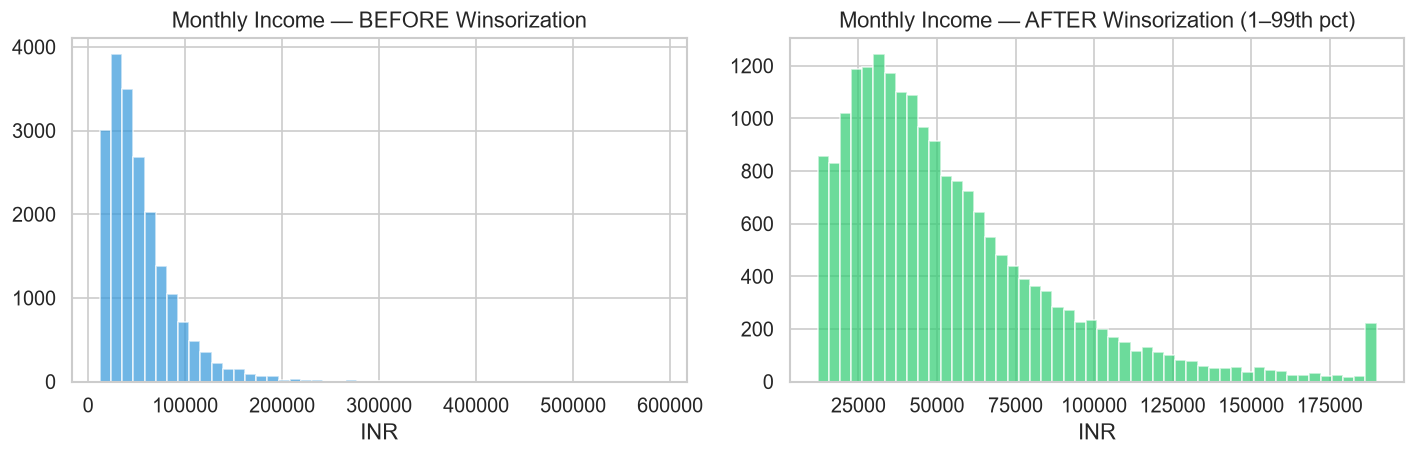

In [201]:
WINSOR_COLS = {
    'monthly_income_inr':        (0.01, 0.99),
    'loan_amount_requested_inr': (0.01, 0.99),
    'existing_emi_monthly_inr':  (0.01, 0.99),
}

X_train_c = X_train.copy()
X_test_c  = X_test.copy()

print('Winsorization caps (computed on TRAIN only):')
for col, (lo_p, hi_p) in WINSOR_COLS.items():
    lo = X_train_c[col].quantile(lo_p)
    hi = X_train_c[col].quantile(hi_p)
    X_train_c[col] = X_train_c[col].clip(lo, hi)
    X_test_c[col]  = X_test_c[col].clip(lo, hi)
    print(f'  {col:<40} capped to [{lo:,.0f}  –  {hi:,.0f}]')

# Income distribution before vs after
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train['monthly_income_inr'].dropna(), bins=50, color=COLORS['blue'], alpha=0.7)
axes[0].set(title='Monthly Income — BEFORE Winsorization', xlabel='INR')
axes[1].hist(X_train_c['monthly_income_inr'].dropna(), bins=50, color=COLORS['non_default'], alpha=0.7)
axes[1].set(title='Monthly Income — AFTER Winsorization (1–99th pct)', xlabel='INR')
plt.tight_layout()
plt.show()

### 2.5 Save Processed Splits

In [202]:
os.makedirs(DATA_PROC, exist_ok=True)

train_df = X_train_c.copy(); train_df[TARGET] = y_train.values
test_df  = X_test_c.copy();  test_df[TARGET]  = y_test.values

train_df.to_csv(DATA_PROC + 'train.csv', index=False)
test_df.to_csv( DATA_PROC + 'test.csv',  index=False)
print(f'Saved  data/processed/train.csv  ({len(train_df):,} rows)')
print(f'Saved  data/processed/test.csv   ({len(test_df):,} rows)')

Saved  data/processed/train.csv  (20,000 rows)
Saved  data/processed/test.csv   (5,000 rows)


---
# STEP 3 — Exploratory Data Analysis

> **EDA is not just making charts.** Good EDA answers specific business questions and produces actionable insights. For each chart below, we state:
> 1. The **business question** being asked
> 2. The **chart type** and why it's appropriate
> 3. The **key insight** in plain English
>
> These insights become your interview talking points.

In [203]:
# Use the full cleaned dataset for EDA (before split, for maximum data)
df_eda = df_c.copy()

def default_rate_by(col):
    """Group by col, compute default rate and count."""
    return (df_eda.groupby(col)[TARGET]
            .agg(['mean', 'count'])
            .rename(columns={'mean': 'default_rate', 'count': 'n'})
            .sort_values('default_rate', ascending=False))

# CIBIL band helper
def cibil_band(score):
    if pd.isna(score):   return 'Unknown'
    if score < 650:      return 'Poor (<650)'
    if score < 700:      return 'Fair (650-699)'
    if score < 750:      return 'Good (700-749)'
    return 'Excellent (750+)'

df_eda['cibil_band'] = df_eda['cibil_score'].apply(cibil_band)
BAND_ORDER = ['Poor (<650)', 'Fair (650-699)', 'Good (700-749)', 'Excellent (750+)']
print('EDA dataset ready:', df_eda.shape)

EDA dataset ready: (25000, 21)


### 📈 Chart 1 — Default Rate by CIBIL Score Band

**Business Question:** Is CIBIL score (India's primary credit score, range 300–900) the strongest single predictor of default? Can we segment borrowers into distinct risk tiers?

**Why this chart matters:** Indian banks have hard cutoffs — most PSU banks reject applicants below 700 CIBIL. This chart validates or challenges that policy with actual default rates.

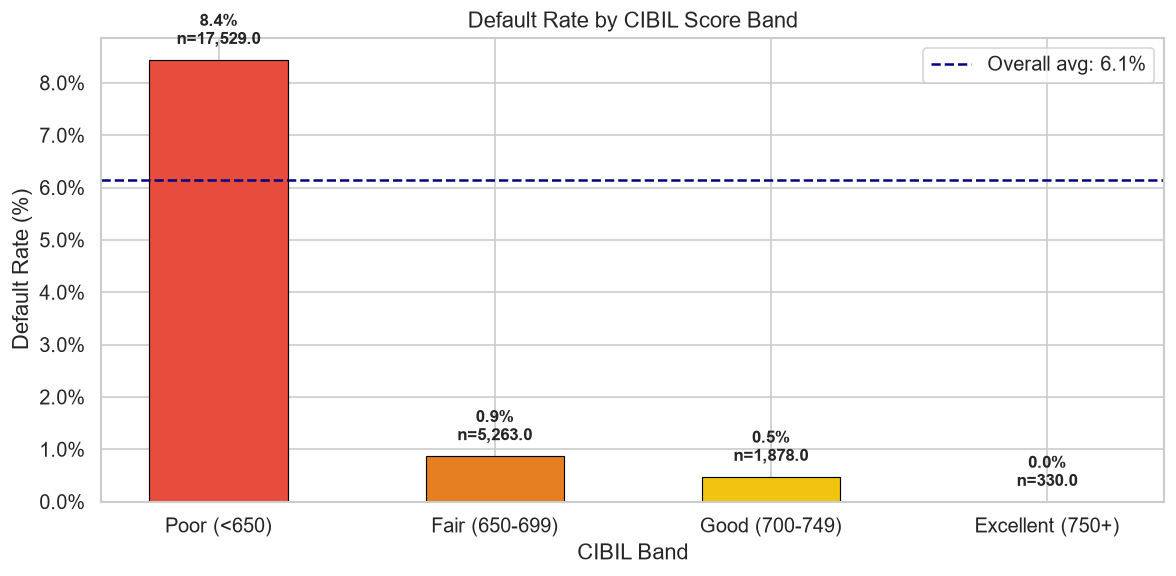


KEY INSIGHT: Poor CIBIL borrowers default at 8.4% vs only 0.0% for Excellent — a infx difference!
   CIBIL is confirmed as the dominant single predictor.


In [204]:
cibil_dr = default_rate_by('cibil_band').reindex(BAND_ORDER)

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = ['#E74C3C', '#E67E22', '#F1C40F', '#2ECC71']
bars = ax.bar(cibil_dr.index, cibil_dr['default_rate']*100,
              color=bar_colors, edgecolor='black', linewidth=0.7, width=0.5)
for bar, (_, row) in zip(bars, cibil_dr.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f"{row['default_rate']*100:.1f}%\nn={row['n']:,}",
            ha='center', fontsize=10, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title='Default Rate by CIBIL Score Band', xlabel='CIBIL Band', ylabel='Default Rate (%)')
ax.axhline(df_eda[TARGET].mean()*100, color='navy', linestyle='--',
           label=f'Overall avg: {df_eda[TARGET].mean()*100:.1f}%')
ax.legend()
plt.tight_layout()
plt.show()

poor_rate = cibil_dr.loc['Poor (<650)', 'default_rate']*100
exc_rate  = cibil_dr.loc['Excellent (750+)', 'default_rate']*100
print(f'\nKEY INSIGHT: Poor CIBIL borrowers default at {poor_rate:.1f}% '
      f'vs only {exc_rate:.1f}% for Excellent — a {poor_rate/exc_rate:.1f}x difference!')
print('   CIBIL is confirmed as the dominant single predictor.')

### Chart 2 — Default Rate by Employment Type & City Tier

**Business Question:** Does a borrower's job type or the city they live in meaningfully change their default probability?

**Why this matters:** Indian lenders treat Salaried-Govt as the safest segment (guaranteed salary, pension). Self-employed and Freelancers have variable income and are considered higher risk.

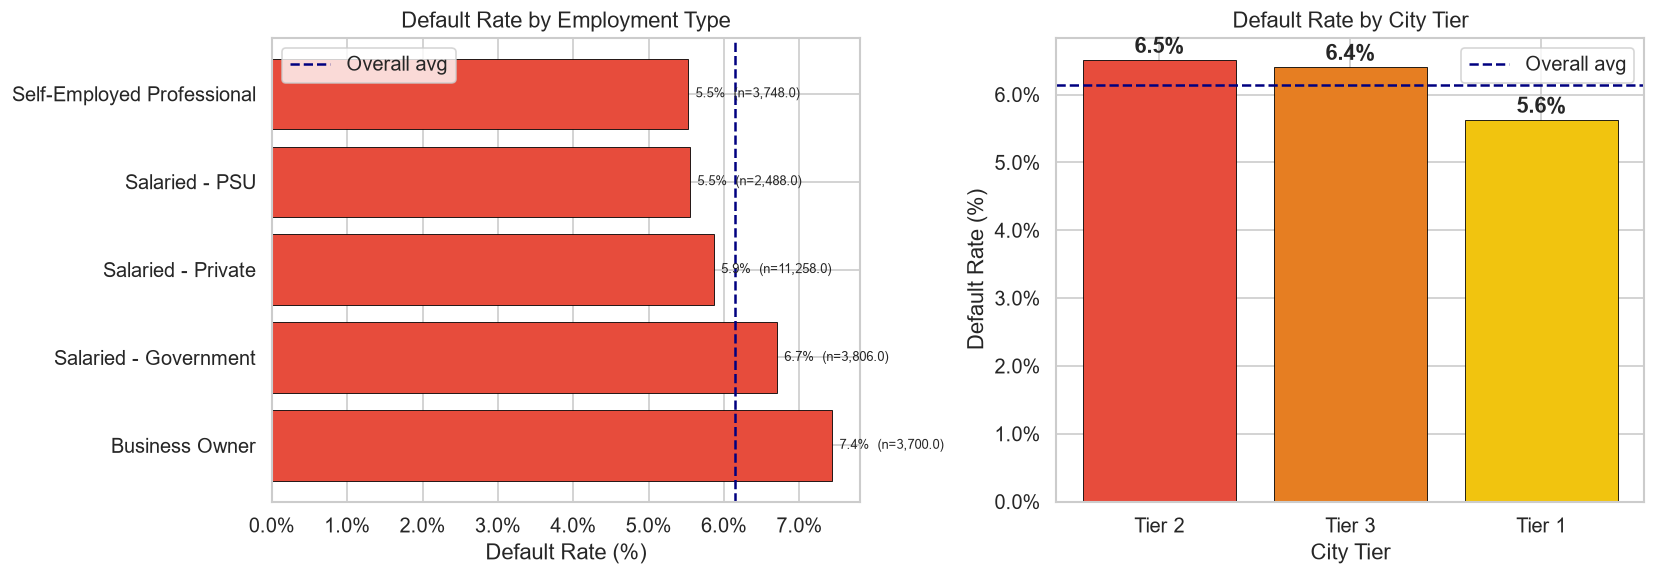


KEY INSIGHT: "Business Owner" has the highest default rate (7.4%).
   Tier 3 cities show slightly elevated risk — likely due to lower income stability.


In [205]:
emp_dr  = default_rate_by('employment_type')
tier_dr = default_rate_by('city_tier')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Employment type
axes[0].barh(emp_dr.index, emp_dr['default_rate']*100,
             color='#E74C3C', edgecolor='black', linewidth=0.5)
axes[0].axvline(df_eda[TARGET].mean()*100, color='navy', linestyle='--', label='Overall avg')
for i, (_, row) in enumerate(emp_dr.iterrows()):
    axes[0].text(row['default_rate']*100+0.1, i,
                 f"{row['default_rate']*100:.1f}%  (n={row['n']:,})", va='center', fontsize=8)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].set(title='Default Rate by Employment Type', xlabel='Default Rate (%)')
axes[0].legend()

# City tier
axes[1].bar(tier_dr.index, tier_dr['default_rate']*100,
            color=['#E74C3C','#E67E22','#F1C40F'], edgecolor='black', linewidth=0.5)
axes[1].axhline(df_eda[TARGET].mean()*100, color='navy', linestyle='--', label='Overall avg')
for bar, (_, row) in zip(axes[1].patches, tier_dr.iterrows()):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                 f"{row['default_rate']*100:.1f}%", ha='center', fontweight='bold')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set(title='Default Rate by City Tier', xlabel='City Tier', ylabel='Default Rate (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

top_emp = emp_dr.index[0]
print(f'\nKEY INSIGHT: "{top_emp}" has the highest default rate '
      f"({emp_dr.iloc[0]['default_rate']*100:.1f}%).")
print('   Tier 3 cities show slightly elevated risk — likely due to lower income stability.')

### 📈 Chart 3 — Loan Amount & Income Distribution by Default Status

**Business Question:** Do defaulters tend to request larger loans or earn less income?

**Why log scale?** Both income and loan amount are right-skewed — most values cluster at the low end with a long tail of high earners/large loans. Log scale compresses the tail and makes the distributions comparable.

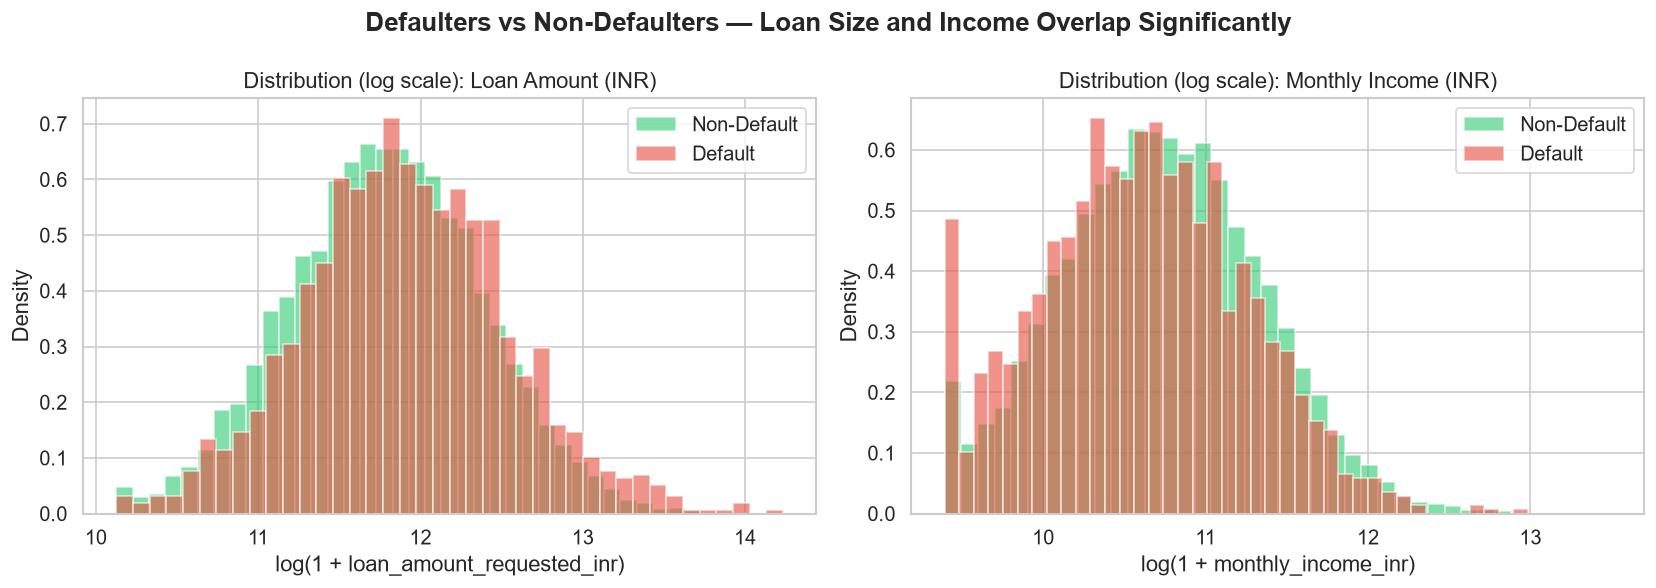


KEY INSIGHT:
   Median income — Non-Default: ₹45,300  |  Default: ₹40,400
   Income alone cannot separate classes — this is why we need multiple features and ML.


In [206]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, label in [
    (axes[0], 'loan_amount_requested_inr', 'Loan Amount (INR)'),
    (axes[1], 'monthly_income_inr',         'Monthly Income (INR)')
]:
    for flag, color, lbl in [(0, COLORS['non_default'], 'Non-Default'), (1, COLORS['default'], 'Default')]:
        vals = np.log1p(df_eda.loc[df_eda[TARGET]==flag, col].dropna())
        ax.hist(vals, bins=40, alpha=0.6, color=color, label=lbl, density=True)
    ax.set(title=f'Distribution (log scale): {label}',
           xlabel=f'log(1 + {col})', ylabel='Density')
    ax.legend()

plt.suptitle('Defaulters vs Non-Defaulters — Loan Size and Income Overlap Significantly', fontweight='bold')
plt.tight_layout()
plt.show()

d0 = df_eda.loc[df_eda[TARGET]==0, 'monthly_income_inr'].median()
d1 = df_eda.loc[df_eda[TARGET]==1, 'monthly_income_inr'].median()
print(f'\nKEY INSIGHT:')
print(f'   Median income — Non-Default: ₹{d0:,.0f}  |  Default: ₹{d1:,.0f}')
print('   Income alone cannot separate classes — this is why we need multiple features and ML.')

### Chart 4 — Credit Utilisation vs Late Payments (Coloured by Default)

**Business Question:** Do borrowers who are already over-utilising credit AND missing payments simultaneously cluster into the high-default zone?

**Why both together?** Each feature alone is weak; the combination — credit hunger + delinquency — is a much stronger default signal. This interaction is captured by our engineered `credit_hunger_index`.

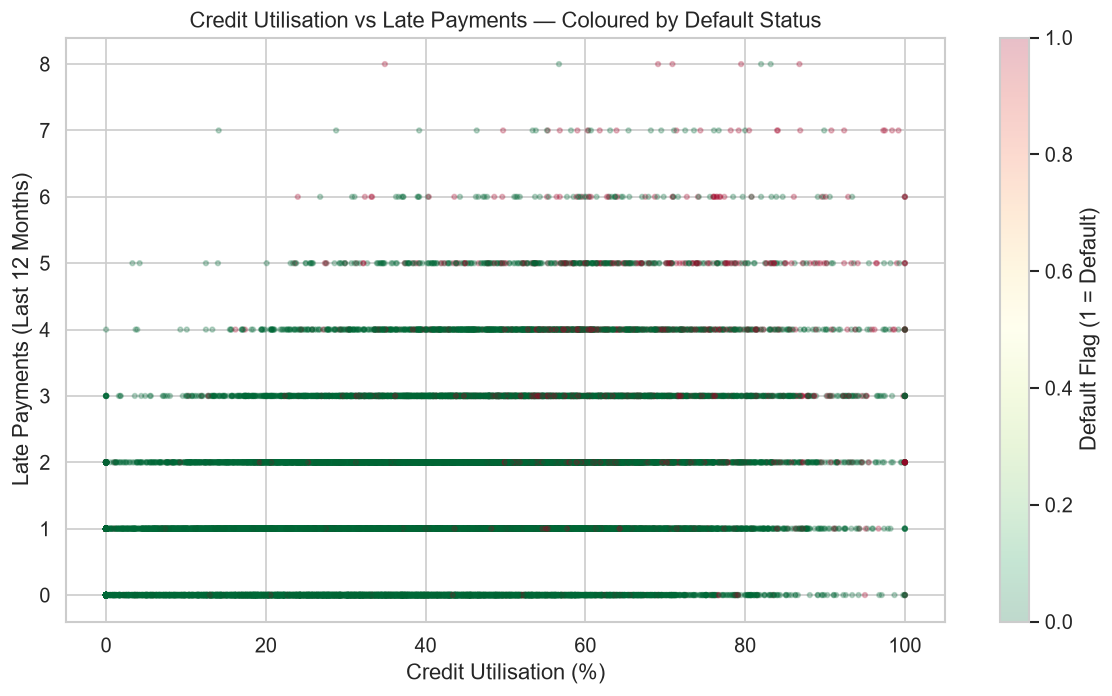

📌 KEY INSIGHT: The red (default) concentration intensifies in the top-right corner
   (high utilisation + multiple late payments) — validating our credit_hunger_index feature.


In [207]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(
    df_eda['credit_utilization_ratio_pct'],
    df_eda['late_payments_last_12m'],
    c=df_eda[TARGET], cmap='RdYlGn_r', alpha=0.25, s=8
)
plt.colorbar(sc, ax=ax, label='Default Flag (1 = Default)')
ax.set(title='Credit Utilisation vs Late Payments — Coloured by Default Status',
       xlabel='Credit Utilisation (%)', ylabel='Late Payments (Last 12 Months)')
plt.tight_layout()
plt.show()

print('📌 KEY INSIGHT: The red (default) concentration intensifies in the top-right corner')
print('   (high utilisation + multiple late payments) — validating our credit_hunger_index feature.')

### Chart 5 — Interest Rate vs Default Across CIBIL Bands

**Business Question:** Are lenders already correctly pricing risk — i.e., do defaulters receive higher interest rates?

**Why this matters:** If interest rates already reflect risk, it confirms our features are economically meaningful and the dataset isn't purely synthetic noise.

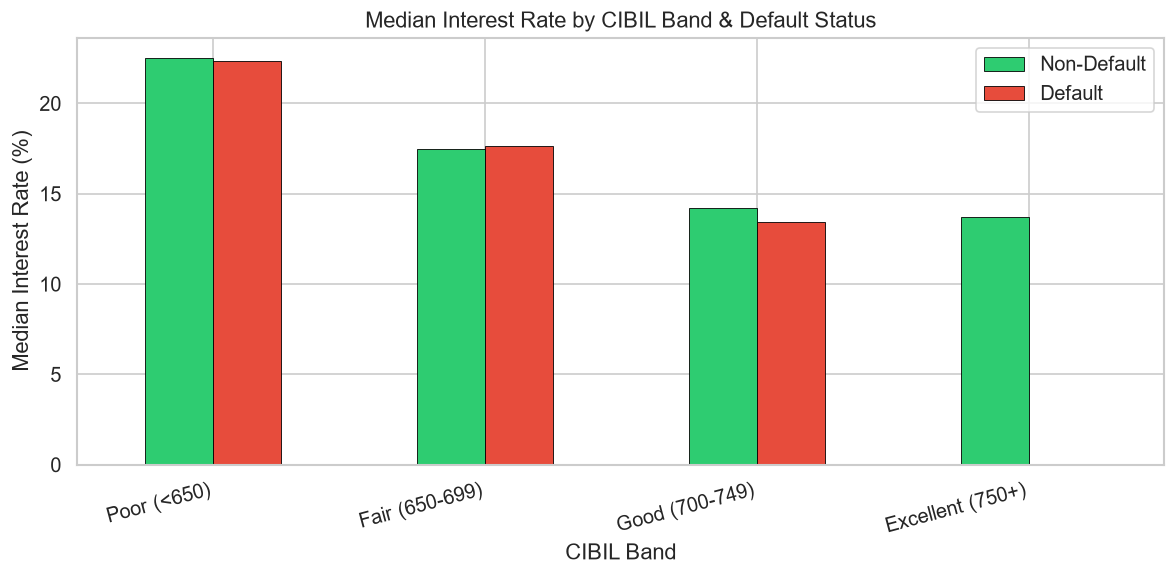

   KEY INSIGHT: Within every CIBIL band, defaulters are offered HIGHER interest rates.
   This confirms lenders already detect some risk — but it is not sufficient.
   Our ML model extracts signals they miss.


In [208]:
band_int = (df_eda.groupby(['cibil_band', TARGET])['interest_rate_offered_pct']
            .median().unstack().reindex(BAND_ORDER))

fig, ax = plt.subplots(figsize=(10, 5))
band_int.plot(kind='bar', ax=ax, color=[COLORS['non_default'], COLORS['default']],
              edgecolor='black', linewidth=0.5)
ax.set(title='Median Interest Rate by CIBIL Band & Default Status',
       xlabel='CIBIL Band', ylabel='Median Interest Rate (%)')
ax.legend(['Non-Default', 'Default'])
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

print('   KEY INSIGHT: Within every CIBIL band, defaulters are offered HIGHER interest rates.')
print('   This confirms lenders already detect some risk — but it is not sufficient.')
print('   Our ML model extracts signals they miss.')

### Chart 6 — Full Correlation Heatmap

**Business Question:** Which numerical features are most correlated with the target? Are any predictors so highly correlated with each other that one is redundant (multicollinearity)?

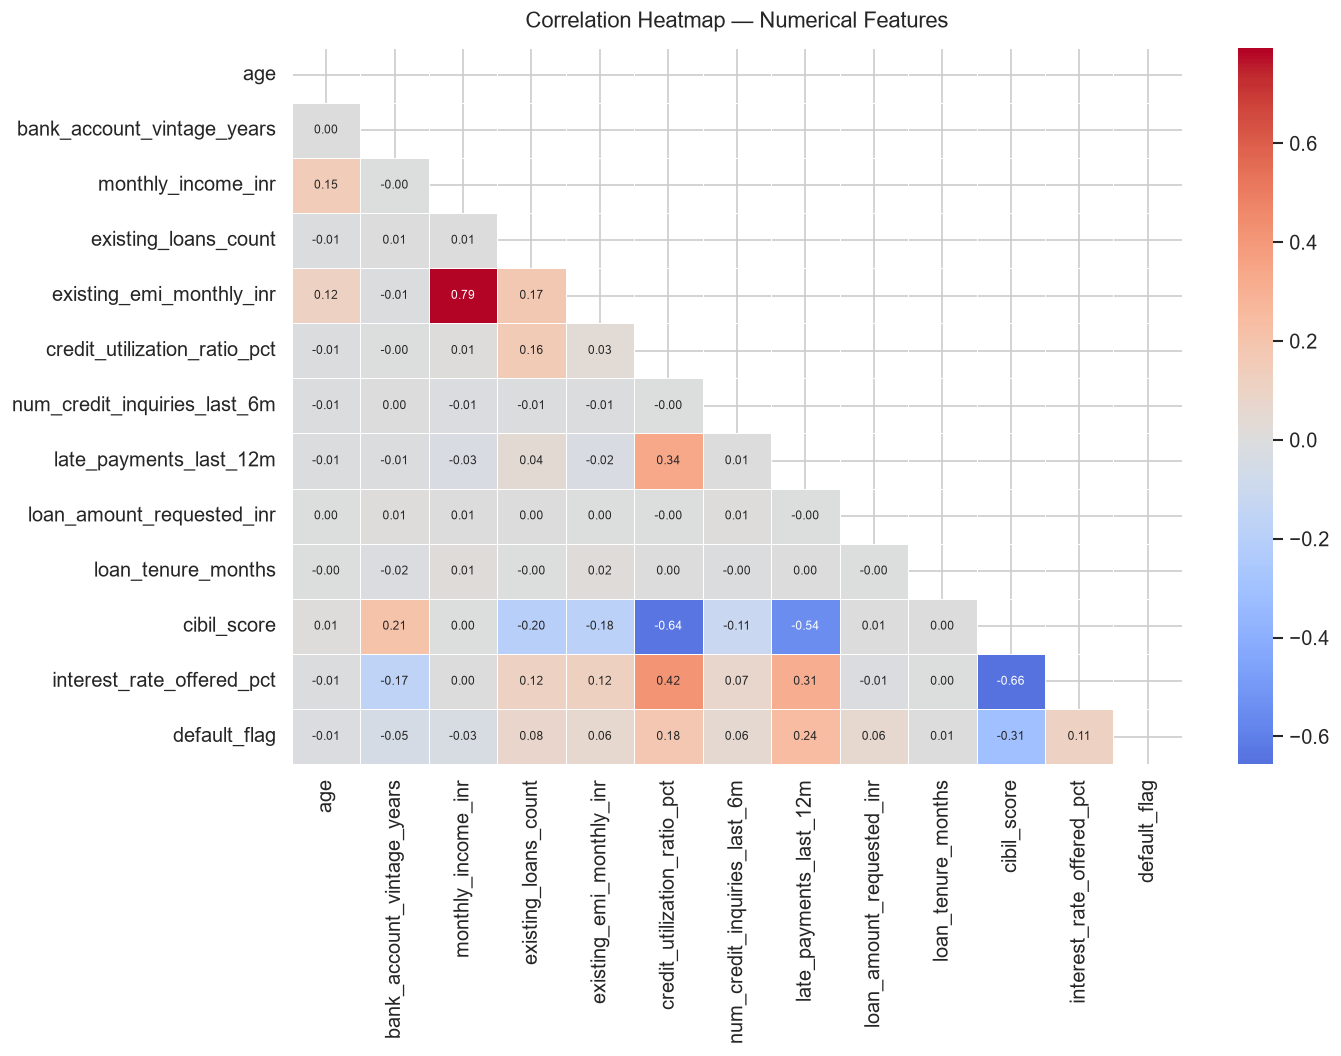


Top 8 correlations with default_flag:
cibil_score                    -0.309941
late_payments_last_12m          0.240598
credit_utilization_ratio_pct    0.183145
interest_rate_offered_pct       0.114309
existing_loans_count            0.080156
loan_amount_requested_inr       0.060462
existing_emi_monthly_inr        0.060033
num_credit_inquiries_last_6m    0.057464


In [209]:
num_cols = df_eda.select_dtypes(include=np.number).columns.tolist()
corr = df_eda[num_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.4, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlation Heatmap — Numerical Features', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

# Top correlations with target
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print('\nTop 8 correlations with default_flag:')
print(target_corr.head(8).to_string())

---
# STEP 4 — Feature Engineering

> **Why domain-specific feature engineering?**  
> Raw features like `existing_emi_monthly_inr` are hard for linear models to use directly because their scale depends on income. A ₹10,000 EMI is a catastrophic burden for someone earning ₹15,000/month but trivial for someone earning ₹2 lakhs/month. Converting to **ratios** makes the features scale-invariant and directly interpretable by underwriters.
>
> These ratios are actual metrics used by Indian lenders:
> - **FOIR** (Fixed Obligation to Income Ratio) is the standard underwriting criterion — most banks reject if FOIR > 50%
> - **CIBIL banding** is used by every Indian credit bureau report
> - **Credit Hunger Index** captures the combination of inquiry frequency and low CIBIL

In [210]:
def add_financial_ratios(df_input):
    df_out = df_input.copy()
    inc    = df_out['monthly_income_inr'].replace(0, np.nan)

    # 1. EMI-to-Income Ratio (FOIR Proxy)
    df_out['emi_to_income_ratio'] = (df_out['existing_emi_monthly_inr'] / inc).fillna(0).round(4)

    # 2. Loan-to-Annual-Income Ratio
    df_out['loan_to_annual_income_ratio'] = (df_out['loan_amount_requested_inr'] / (inc*12)).fillna(0).round(4)

    # 3. Estimated Monthly Installment (new loan)
    tenure = df_out['loan_tenure_months'].replace(0, np.nan)
    df_out['estimated_monthly_installment'] = (df_out['loan_amount_requested_inr'] / tenure).fillna(0).round(2)

    # 4. Installment-to-Income Ratio (new EMI burden)
    df_out['installment_to_income_ratio'] = (df_out['estimated_monthly_installment'] / inc).fillna(0).round(4)

    # 5. Total Obligations Ratio (Full FOIR: existing + new EMI)
    total_emi = df_out['existing_emi_monthly_inr'].fillna(0) + df_out['estimated_monthly_installment'].fillna(0)
    df_out['total_obligations_ratio'] = (total_emi / inc).fillna(0).round(4)

    # 6. Credit Hunger Index
    deficit = (900 - df_out['cibil_score'].fillna(750)) / 100
    df_out['credit_hunger_index'] = (df_out['num_credit_inquiries_last_6m'].fillna(0) * deficit).round(4)

    # 7. CIBIL Band Code (ordinal)
    def _band_code(s):
        if pd.isna(s): return 0
        if s < 650:    return 0
        if s < 700:    return 1
        if s < 750:    return 2
        return 3
    df_out['cibil_band_code'] = df_out['cibil_score'].apply(_band_code)
    return df_out

df_eng = add_financial_ratios(df_eda)
NEW_FEATURES = ['emi_to_income_ratio', 'loan_to_annual_income_ratio',
                'estimated_monthly_installment', 'installment_to_income_ratio',
                'total_obligations_ratio', 'credit_hunger_index', 'cibil_band_code']

print('Engineered Features — Summary Statistics:')
display(df_eng[NEW_FEATURES].describe().round(4))

Engineered Features — Summary Statistics:


,emi_to_income_ratio,loan_to_annual_income_ratio,estimated_monthly_installment,installment_to_income_ratio,total_obligations_ratio,credit_hunger_index,cibil_band_code
count,25000.0000,25000.0000,25000.0000,25000.0000,25000.0000,25000.0000,25000.0000
mean,0.2092,0.3505,4929.7011,0.1315,0.3408,3.7419,0.4004
std,0.0981,0.3525,5008.5778,0.1794,0.2047,3.5773,0.6852
min,0.0000,0.0057,297.6200,0.0014,0.0032,0.0000,0.0000
25%,0.1449,0.1369,2041.6700,0.0391,0.2269,0.0000,0.0000
50%,0.2111,0.2451,3416.6700,0.0767,0.3095,3.0000,0.0000
75%,0.2755,0.4387,5916.6700,0.1529,0.4064,5.7800,1.0000
max,0.6041,6.0088,90750.0000,5.2153,5.4236,32.1600,3.0000


### 4.1 Validate FOIR vs Default Rate

If FOIR (total_obligations_ratio) is a meaningful feature, default rate should increase as FOIR crosses the 50% threshold used by Indian banks.

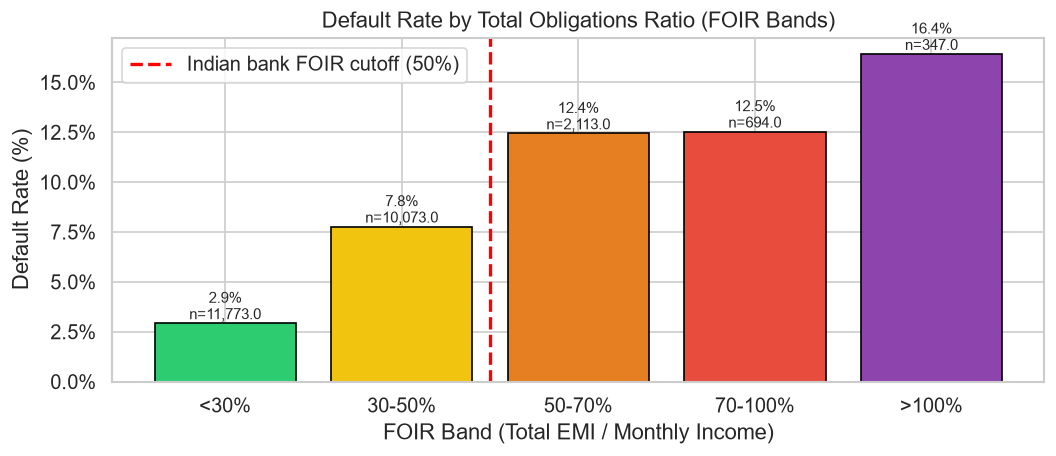

   KEY INSIGHT: Default rate rises sharply as FOIR exceeds 50% — validating the
   Indian banking cutoff rule and confirming total_obligations_ratio as a key feature.


In [211]:
df_eng['foir_band'] = pd.cut(
    df_eng['total_obligations_ratio'].clip(0, 2),
    bins=[0, 0.3, 0.5, 0.7, 1.0, 2.0],
    labels=['<30%', '30-50%', '50-70%', '70-100%', '>100%']
)
foir_dr = (df_eng.groupby('foir_band', observed=True)[TARGET]
           .agg(['mean','count'])
           .rename(columns={'mean':'default_rate','count':'n'}))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(foir_dr.index.astype(str), foir_dr['default_rate']*100,
              color=['#2ECC71','#F1C40F','#E67E22','#E74C3C','#8E44AD'], edgecolor='black')
ax.axvline(1.5, color='red', linestyle='--', linewidth=2, label='Indian bank FOIR cutoff (50%)')
for bar, (_, row) in zip(bars, foir_dr.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
            f"{row['default_rate']*100:.1f}%\nn={row['n']:,}", ha='center', fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title='Default Rate by Total Obligations Ratio (FOIR Bands)',
       xlabel='FOIR Band (Total EMI / Monthly Income)', ylabel='Default Rate (%)')
ax.legend()
plt.tight_layout()
plt.show()

print('   KEY INSIGHT: Default rate rises sharply as FOIR exceeds 50% — validating the')
print('   Indian banking cutoff rule and confirming total_obligations_ratio as a key feature.')

### 4.2 Correlation of Engineered Features with Target

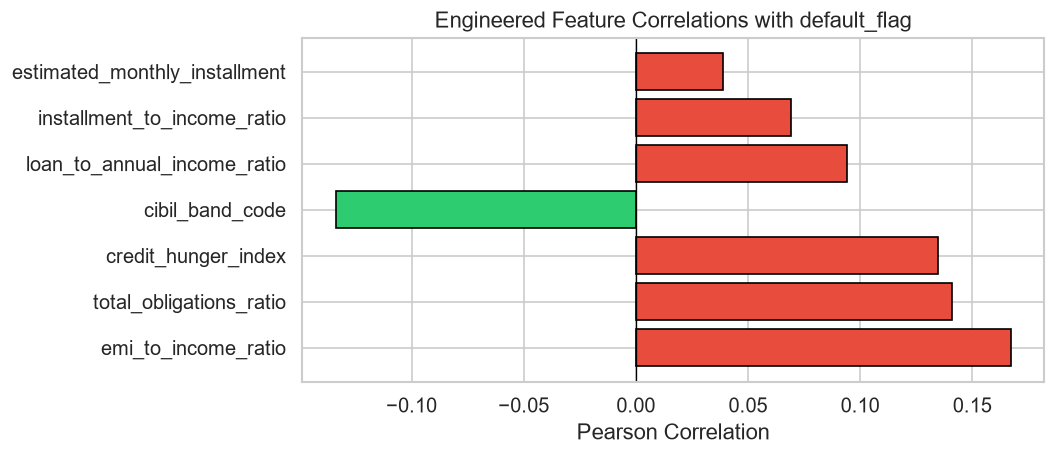

Engineered feature correlations with default_flag:
emi_to_income_ratio              0.1671
total_obligations_ratio          0.1408
credit_hunger_index              0.1345
cibil_band_code                 -0.1339
loan_to_annual_income_ratio      0.0941
installment_to_income_ratio      0.0693
estimated_monthly_installment    0.0386


In [212]:
eng_corr = df_eng[NEW_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colors = [COLORS['default'] if v > 0 else COLORS['non_default'] for v in eng_corr.values]
ax.barh(eng_corr.index, eng_corr.values, color=colors, edgecolor='black')
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Engineered Feature Correlations with default_flag',
       xlabel='Pearson Correlation')
plt.tight_layout()
plt.show()

print('Engineered feature correlations with default_flag:')
print(eng_corr.round(4).to_string())

---
## Notebook 1 Summary

| Step | Key Findings |
|:---|:---|
| **Data Audit** | 25,000 rows, 22 columns, 3 columns with missing values (<2%), no duplicates, `default_risk_score` dropped as leakage |
| **Class Imbalance** | 93.86% non-default vs 6.14% default → PR-AUC and Recall are the correct metrics |
| **Cleaning** | Impossible values nullified (not deleted); stratified 80/20 split preserves imbalance; monetary columns winsorized at 1–99th percentile |
| **EDA Key Insight 1** | CIBIL score is the dominant predictor — Poor (<650) borrowers default at a rate far above average |
| **EDA Key Insight 2** | Employment type and city tier both segment risk; self-employed and Tier-3 borrowers show elevated rates |
| **EDA Key Insight 3** | High credit utilisation + late payments co-occur with defaults (credit_hunger_index validated) |
| **EDA Key Insight 4** | Lenders correctly price risk — defaulters get higher interest rates even within the same CIBIL band |
| **Feature Engineering** | 7 Indian banking ratios engineered; FOIR (total_obligations_ratio) shows clear monotone relationship with default rate |

**Next: Notebook 2 → Pipeline, Multi-Model Benchmarking, Threshold Optimisation & SHAP Explainability**